In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import ast

In [3]:
df = pd.read_csv('data/methods.tsv', sep='\t', header=None)
df.columns = ['Unnamed: 0', 'precision', 'recall', 'f1-score', 'support', 'split', 'method', 'hash', 'method_params', 'task', 'epoch']
df = df[df['Unnamed: 0'] == 'accuracy'].copy()
df['accuracy'] = pd.to_numeric(df['precision'], errors='coerce')
df['method_params'] = df['method_params'].apply(lambda x: str(x) if not isinstance(x, str) else x)
df['learning_rate'] = df['method_params'].apply(lambda x: ast.literal_eval(x).get('lr', np.nan))
df['batch_size'] = df['method_params'].apply(lambda x: ast.literal_eval(x).get('batch_size', np.nan))
df['scoring_method'] = df['method_params'].apply(lambda x: ast.literal_eval(x).get('scoring', np.nan))
df

,Unnamed: 0,precision,recall,f1-score,support,split,method,hash,method_params,task,epoch,accuracy,learning_rate,batch_size,scoring_method
4,accuracy,0.625,0.625,0.625,0.625,0,ct_pb_mr,005e1b053d,{'norm': 0},pbmc_scgpt,NaN,0.625000,NaN,NaN,NaN
10,accuracy,0.875,0.875,0.875,0.875,1,ct_pb_mr,005e1b053d,{'norm': 0},pbmc_scgpt,NaN,0.875000,NaN,NaN,NaN
16,accuracy,0.25,0.25,0.25,0.25,2,ct_pb_mr,005e1b053d,{'norm': 0},pbmc_scgpt,NaN,0.250000,NaN,NaN,NaN
22,accuracy,0.5,0.5,0.5,0.5,3,ct_pb_mr,005e1b053d,{'norm': 0},pbmc_scgpt,NaN,0.500000,NaN,NaN,NaN
28,accuracy,0.2857142857142857,0.2857142857142857,0.2857142857142857,0.2857142857142857,4,ct_pb_mr,005e1b053d,{'norm': 0},pbmc_scgpt,NaN,0.285714,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19887,accuracy,0.7628292224080268,0.7628292224080268,0.7628292224080268,0.7628292224080268,0,multigrate_mil_reg,ffb98046f8,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",pbmc_pca,49.0,0.762829,0.0001,256.0,attn
19893,accuracy,0.8706462414638648,0.8706462414638648,0.8706462414638648,0.8706462414638648,1,multigrate_mil_reg,ffb98046f8,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",pbmc_pca,49.0,0.870646,0.0001,256.0,attn
19899,accuracy,0.6997659061528249,0.6997659061528249,0.6997659061528249,0.6997659061528249,2,multigrate_mil_reg,ffb98046f8,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",pbmc_pca,49.0,0.699766,0.0001,256.0,attn
19905,accuracy,0.8748167283390351,0.8748167283390351,0.8748167283390351,0.8748167283390351,3,multigrate_mil_reg,ffb98046f8,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",pbmc_pca,49.0,0.874817,0.0001,256.0,attn


In [4]:
# Only keep configs with all 5 splits
split_counts = df.groupby(['hash', 'method', 'task', 'epoch', 'method_params'])['split'].nunique().reset_index()
full_configs = split_counts[split_counts['split'] == 5]
df_full = pd.merge(df, full_configs.drop('split', axis=1), on=['hash', 'method', 'task', 'epoch', 'method_params'])
df_full

,Unnamed: 0,precision,recall,f1-score,support,split,method,hash,method_params,task,epoch,accuracy,learning_rate,batch_size,scoring_method
0,accuracy,0.8703752090301003,0.8703752090301003,0.8703752090301003,0.8703752090301003,0,multigrate_mil_reg,00eb5dd690,"{'lr': 1e-05, 'categorical_covariate_keys': ""[...",pbmc_scvi,99.0,0.870375,0.00001,1024.0,gated_attn
1,accuracy,0.7779,0.7779,0.7779,0.7779,0,multigrate_mil_reg,00eb5dd690,"{'lr': 1e-05, 'categorical_covariate_keys': ""[...",pbmc_scvi,49.0,0.777900,0.00001,1024.0,gated_attn
2,accuracy,0.698605215281989,0.698605215281989,0.698605215281989,0.698605215281989,1,multigrate_mil_reg,00eb5dd690,"{'lr': 1e-05, 'categorical_covariate_keys': ""[...",pbmc_scvi,49.0,0.698605,0.00001,1024.0,gated_attn
3,accuracy,0.79375,0.79375,0.79375,0.79375,1,multigrate_mil_reg,00eb5dd690,"{'lr': 1e-05, 'categorical_covariate_keys': ""[...",pbmc_scvi,99.0,0.793750,0.00001,1024.0,gated_attn
4,accuracy,0.6731770378393487,0.6731770378393487,0.6731770378393487,0.6731770378393487,2,multigrate_mil_reg,00eb5dd690,"{'lr': 1e-05, 'categorical_covariate_keys': ""[...",pbmc_scvi,49.0,0.673177,0.00001,1024.0,gated_attn
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020,accuracy,0.7628292224080268,0.7628292224080268,0.7628292224080268,0.7628292224080268,0,multigrate_mil_reg,ffb98046f8,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",pbmc_pca,49.0,0.762829,0.00010,256.0,attn
2021,accuracy,0.8706462414638648,0.8706462414638648,0.8706462414638648,0.8706462414638648,1,multigrate_mil_reg,ffb98046f8,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",pbmc_pca,49.0,0.870646,0.00010,256.0,attn
2022,accuracy,0.6997659061528249,0.6997659061528249,0.6997659061528249,0.6997659061528249,2,multigrate_mil_reg,ffb98046f8,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",pbmc_pca,49.0,0.699766,0.00010,256.0,attn
2023,accuracy,0.8748167283390351,0.8748167283390351,0.8748167283390351,0.8748167283390351,3,multigrate_mil_reg,ffb98046f8,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",pbmc_pca,49.0,0.874817,0.00010,256.0,attn


In [5]:
grouped = df_full.groupby(['hash', 'method', 'task', 'epoch', 'method_params', 'learning_rate', 'batch_size', 'scoring_method'])['accuracy'].mean().reset_index()
grouped

,hash,method,task,epoch,method_params,learning_rate,batch_size,scoring_method,accuracy
0,00eb5dd690,multigrate_mil_reg,pbmc_scvi,49.0,"{'lr': 1e-05, 'categorical_covariate_keys': ""[...",0.00001,1024.0,gated_attn,0.668339
1,00eb5dd690,multigrate_mil_reg,pbmc_scvi,99.0,"{'lr': 1e-05, 'categorical_covariate_keys': ""[...",0.00001,1024.0,gated_attn,0.762533
2,0182946e8e,multigrate_mil,pbmc_scvi,49.0,"{'lr': 0.001, 'categorical_covariate_keys': ""[...",0.00100,256.0,gated_attn,0.746079
3,026607420a,multigrate_mil_reg,pbmc_pca,49.0,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",0.00010,1024.0,gated_attn,0.735984
4,033d71d5d8,multigrate_mil_reg,pbmc_scgpt,49.0,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",0.00010,1024.0,attn,0.830146
...,...,...,...,...,...,...,...,...,...
400,fd366ff6dd,multigrate_mil_reg,pbmc_scvi,49.0,"{'lr': 0.001, 'categorical_covariate_keys': ""[...",0.00100,512.0,gated_attn,0.805855
401,ff42efd560,multigrate_mil_reg,pbmc_geneformer,49.0,"{'lr': 0.001, 'categorical_covariate_keys': ""[...",0.00100,1024.0,gated_attn,0.730905
402,ff47e10c71,multigrate_mil_reg,pbmc_scvi,49.0,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",0.00010,512.0,attn,0.789891
403,ff4c8523a5,multigrate_mil,pbmc_scgpt,49.0,"{'lr': 0.01, 'categorical_covariate_keys': ""['...",0.01000,1024.0,max,0.756898


In [17]:
grouped.rename(columns={'scoring_method': 'pooling_function'}, inplace=True)

In [18]:
feature_names = ['learning_rate', 'pooling_function', 'batch_size']

In [20]:
X = grouped[feature_names].copy()
le = LabelEncoder()
X['pooling_function_encoded'] = le.fit_transform(X['pooling_function'].astype(str))
X = X.drop('pooling_function', axis=1)
y = grouped['accuracy']
rf = RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_split=5, min_samples_leaf=2, random_state=42, n_jobs=-1)
rf.fit(X, y)
importances = rf.feature_importances_

In [24]:
rf.feature_names_in_

array(['learning_rate', 'batch_size', 'pooling_function_encoded'],
      dtype=object)

In [22]:
importances

array([0.42836513, 0.23135452, 0.34028035])

/tmp/ipykernel_4093767/2450099818.py:15: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


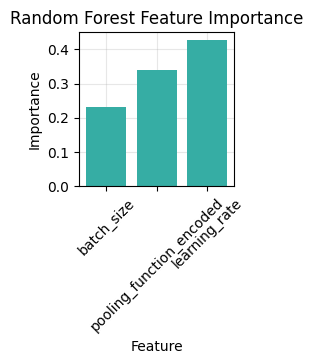

In [28]:
sorted_indices = np.argsort(importances)
sorted_importances = importances[sorted_indices]
sorted_features = np.array(rf.feature_names_in_)[sorted_indices]

palette = sns.color_palette("husl")
color = palette[3]

plt.figure(figsize=(2, 2))
plt.grid(True, alpha=0.3, zorder=1)
bars = plt.bar(sorted_features, sorted_importances, zorder=2, color=color)
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.title('Random Forest Feature Importance')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('figures/random_forest_feature_importance.svg', dpi=300, bbox_inches='tight')
plt.show()
